# House Price Predictor

**Goal:** Predict the price of a house using information like income in the area, house age, number of rooms, and location.

**What I learn in this project:**
1. Loading and exploring data with **pandas**
2. Visualizing data with **matplotlib / seaborn**
3. Splitting data into **train** and **test** sets
4. Training two models: **Linear Regression** and **Random Forest**
5. Measuring how good a model is (**MAE, RMSE, R²**)

**Dataset:** California Housing (built into scikit-learn, so there is nothing to download manually).

## Step 1: Import libraries
Think of these as toolboxes:
- `pandas` → tables of data (like Excel in Python)
- `numpy` → math
- `matplotlib` / `seaborn` → charts
- `sklearn` (scikit-learn) → machine learning models

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Step 2: Load the data
`as_frame=True` gives us a pandas table instead of raw arrays.

- `X` = the **inputs** (features): what we know about each area
- `y` = the **output** (target): the house price we want to predict

In [2]:
data = fetch_california_housing(as_frame=True)
df = data.frame          # full table (features + price)

print("Rows, Columns:", df.shape)
df.head()

Rows, Columns: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


**What do the columns mean?**

| Column | Meaning |
|---|---|
| MedInc | Median income in the area (in tens of thousands of $) |
| HouseAge | Median age of houses |
| AveRooms | Average number of rooms per house |
| AveBedrms | Average number of bedrooms per house |
| Population | People living in the area |
| AveOccup | Average people per house |
| Latitude / Longitude | Location |
| **MedHouseVal** | **Median house price (in $100,000s), this is what we predict** |

## Step 3: Explore the data
Always look at your data before training a model.
- `info()` → column types and whether anything is missing
- `describe()` → min, max, average of each column

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [4]:
df.describe().round(2)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


In [5]:
# Are there missing values? (0 everywhere = good)
df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

## Step 4: Visualize
**Chart 1:** How are house prices spread out?

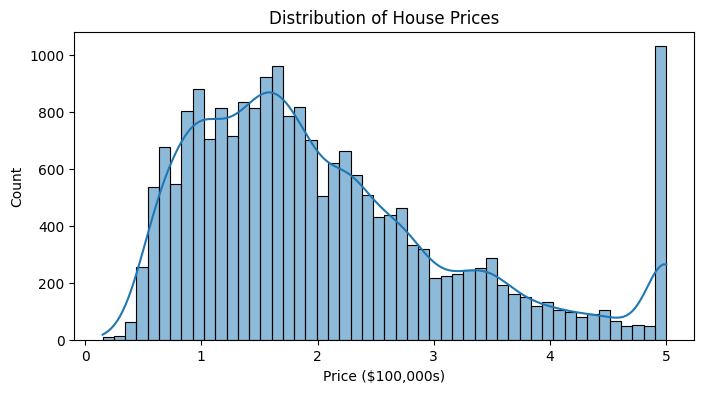

In [6]:
plt.figure(figsize=(8, 4))
sns.histplot(df["MedHouseVal"], bins=50, kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("Price ($100,000s)")
plt.show()

 Notice the spike at 5.0: prices above $500k were capped at 5.0 in this dataset. That's a real-world data issue worth mentioning in  README.

**Chart 2:** Which features are related to price? (correlation heatmap)
Numbers close to **+1** mean "when this goes up, price goes up." Close to **0** means "no clear relation."

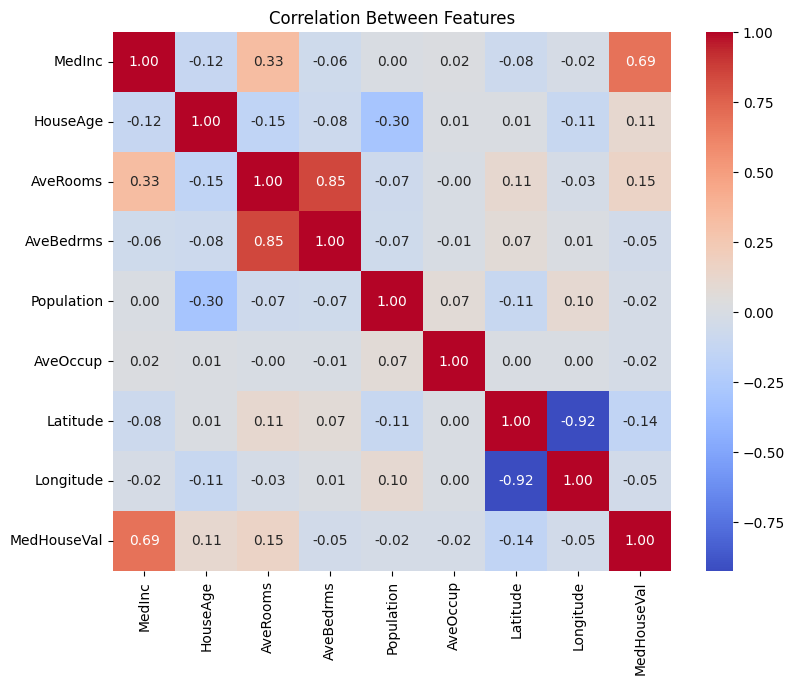

In [7]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Between Features")
plt.show()

 **MedInc (income)** has the strongest link to price (about 0.69). Richer areas → more expensive houses. 

**Chart 3:** Income vs Price

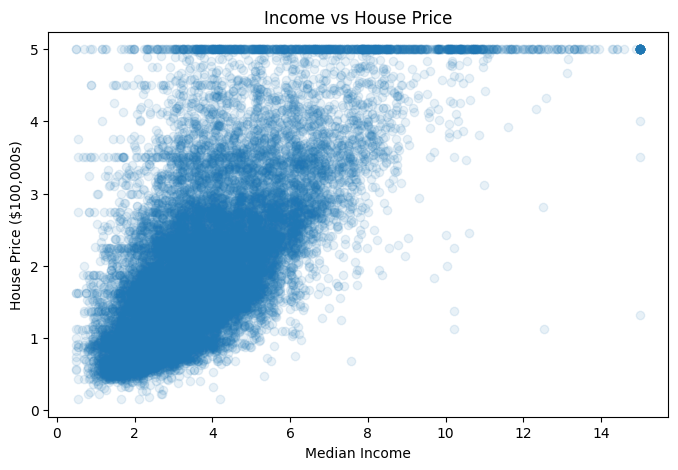

In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(df["MedInc"], df["MedHouseVal"], alpha=0.1)
plt.xlabel("Median Income")
plt.ylabel("House Price ($100,000s)")
plt.title("Income vs House Price")
plt.show()

**Chart 4:** Price by location (it looks like a map of California!)

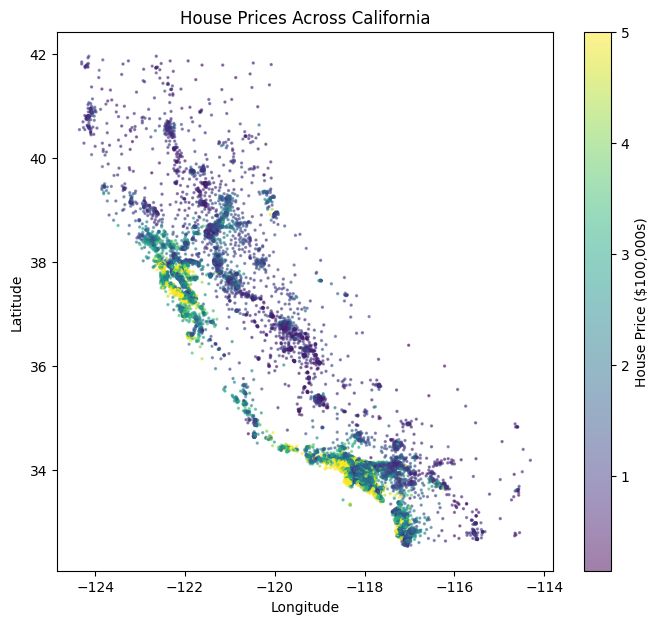

In [9]:
plt.figure(figsize=(8, 7))
plt.scatter(df["Longitude"], df["Latitude"], c=df["MedHouseVal"], cmap="viridis", s=2, alpha=0.5)
plt.colorbar(label="House Price ($100,000s)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("House Prices Across California")
plt.show()

Expensive areas (yellow) are along the coast, near San Francisco and Los Angeles.

## Step 5: Split into training and testing data
I hide 20% of the data from the model. After training, I test on this hidden part.
This tells  how the model would do on **new houses it has never seen**.

`random_state=42` just makes the split the same every time run it.

In [10]:
X = df.drop(columns=["MedHouseVal"])   # inputs
y = df["MedHouseVal"]                  # output (price)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows: ", len(X_test))

Training rows: 16512
Testing rows:  4128


## Step 6: Model 1: Linear Regression
The simplest model. It draws the "best straight line" through the data:

price = (w1 × income) + (w2 × house age) + ... + bias

- `.fit()` → the model **learns** from training data
- `.predict()` → the model **guesses** prices for test data

In [11]:
lr = LinearRegression()
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

## Step 7: How good is it?
I write a small function so we can reuse it for both models.

- **MAE** (Mean Absolute Error): on average, how far off is the guess? *Lower = better.*
- **RMSE** (Root Mean Squared Error): like MAE but punishes big mistakes more. *Lower = better.*
- **R²** score: how much of the price variation the model explains. 1.0 = perfect, 0 = useless. *Higher = better.*

Prices are in $100,000s, so an MAE of 0.53 means "off by about $53,000 on average."

In [12]:
def evaluate(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{name}")
    print(f"  MAE : {mae:.3f}  (≈ ${mae*100000:,.0f} off on average)")
    print(f"  RMSE: {rmse:.3f}")
    print(f"  R²  : {r2:.3f}")
    return {"Model": name, "MAE": mae, "RMSE": rmse, "R2": r2}

lr_results = evaluate("Linear Regression", y_test, lr_pred)

Linear Regression
  MAE : 0.533  (≈ $53,320 off on average)
  RMSE: 0.746
  R²  : 0.576


## Step 8: Model 2: Random Forest
A Random Forest builds **many decision trees** (here, 100) and averages their answers.
Each tree asks yes/no questions like *"Is income > 5? Is it near the coast?"*
It can learn curved, complex patterns that a straight line can't.


In [13]:
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_results = evaluate("Random Forest", y_test, rf_pred)

Random Forest
  MAE : 0.328  (≈ $32,754 off on average)
  RMSE: 0.505
  R²  : 0.805


## Step 9: Compare the two models

In [14]:
results = pd.DataFrame([lr_results, rf_results]).round(3)
results

,Model,MAE,RMSE,R2
0,Linear Regression,0.533,0.746,0.576
1,Random Forest,0.328,0.505,0.805


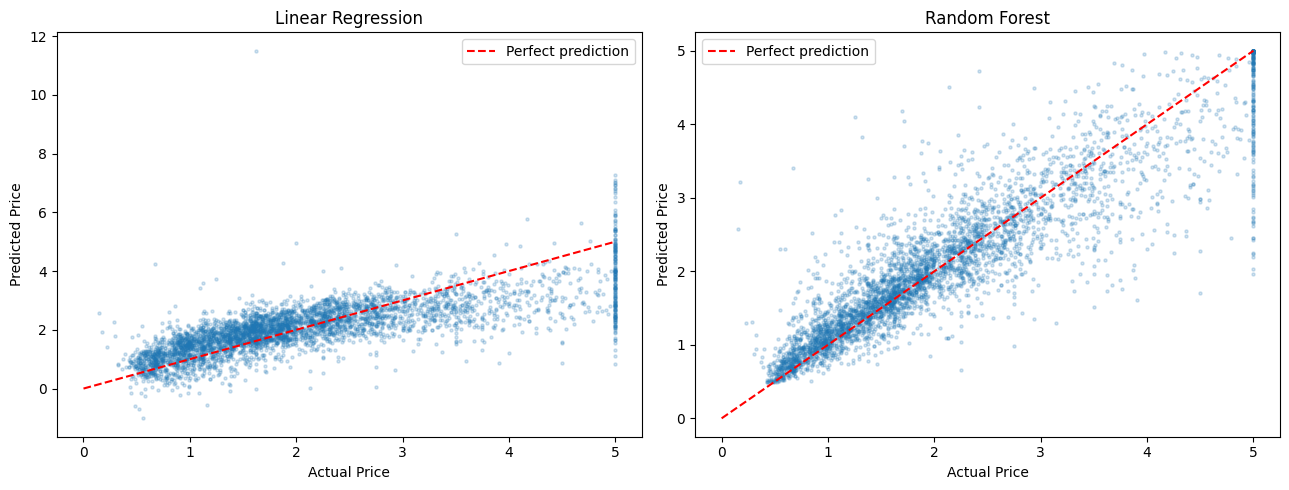

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, pred, title in zip(axes, [lr_pred, rf_pred], ["Linear Regression", "Random Forest"]):
    ax.scatter(y_test, pred, alpha=0.2, s=5)
    ax.plot([0, 5], [0, 5], "r--", label="Perfect prediction")
    ax.set_xlabel("Actual Price")
    ax.set_ylabel("Predicted Price")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

Points close to the red line = good predictions. Random Forest points should hug the line more tightly.

## Step 10: Which features matter most?
Random Forest can tell us which inputs it relied on the most.

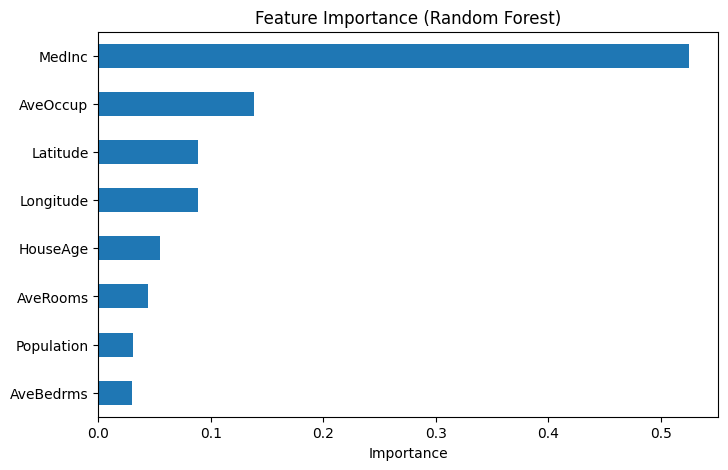

In [16]:
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
importance.plot(kind="barh")
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Importance")
plt.show()

## Step 11: Predict the price of a new house
Let's make up an area and ask the model for a price.

In [17]:
new_house = pd.DataFrame([{
    "MedInc": 8.0,        # high income area ($80,000)
    "HouseAge": 20,
    "AveRooms": 6,
    "AveBedrms": 1,
    "Population": 1000,
    "AveOccup": 3,
    "Latitude": 37.8,     # near San Francisco
    "Longitude": -122.3,
}])

price = rf.predict(new_house)[0]
print(f"Predicted price: ${price * 100000:,.0f}")

Predicted price: $397,904


Try changing `MedInc` or the location and see how the price changes!

## Step 12: Conclusion

**Results on the test set (4,128 houses the models never saw):**

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Linear Regression | 0.533 (≈ $53,300) | 0.746 | 0.576 |
| Random Forest | **0.328 (≈ $32,800)** | **0.505** | **0.805** |

**What I found:**
1. **Random Forest is clearly better.** It explains about 80% of the variation in house prices, compared with about 58% for Linear Regression. Its average error is about $20,500 smaller (around 39% lower). It wins because house prices don't follow a straight line. For example, location matters in a complex way (coast vs inland), and trees can learn patterns like that.
2. **Income is by far the most important feature** (about 0.52 importance), which matches the correlation heatmap (0.69 correlation with price).
3. **Location matters a lot.** Latitude and longitude together are about 0.18, which is more than any single feature except income. The map shows that expensive areas are along the coast near San Francisco and Los Angeles.
4. **Average occupancy (people per house) came second** as a single feature (about 0.14), even though its simple correlation with price was weak. This shows that Random Forest can find **non-linear relationships** that correlation misses.
5. Number of rooms, bedrooms, and population had little effect on their own.
6. The example high-income house near San Francisco was predicted at **about $398,000**, which makes sense given the patterns above.

**Limitations:**
- House prices in the dataset are **capped at $500,000**, so the model can't learn or predict prices above that.
- The data comes from the **1990 US Census**, so the prices are much lower than today's.
- An average error of about $33k is still large for cheaper houses.

**Next ideas to improve:**
- Try **XGBoost** and tune hyperparameters with **GridSearchCV**
- Use **cross-validation** for a more reliable score
- Remove or handle the capped $500k rows and outliers (for example, AveOccup max = 1,243)
- Build a **Streamlit** web app so anyone can enter details and get a price
